# Thesis Reporting Dashboard

This notebook dynamically loads deterministic CSV artifacts dumped during the simulation execution and plots analytical dashboards of the two-stage model pipeline.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Set global seaborn style
sns.set_theme(style="whitegrid")

os.chdir('../')
print("Current Working Directory:", os.getcwd())

Current Working Directory: c:\thesis


## Section 1: Traffic Distribution

This section loads the generated telemetry profiles and visualizes the volume of Service Function Chain requests dynamically introduced into the physical simulation graph.

,Profile,Requests,Avg_Inter_Arrival,Avg_Duration
0,Profile 1 (Low Traffic),1020,19.603454,29.746078
1,Profile 2 (Medium Traffic),4016,4.979431,89.911604
2,Profile 3 (Burst Traffic),16028,1.247657,154.170514


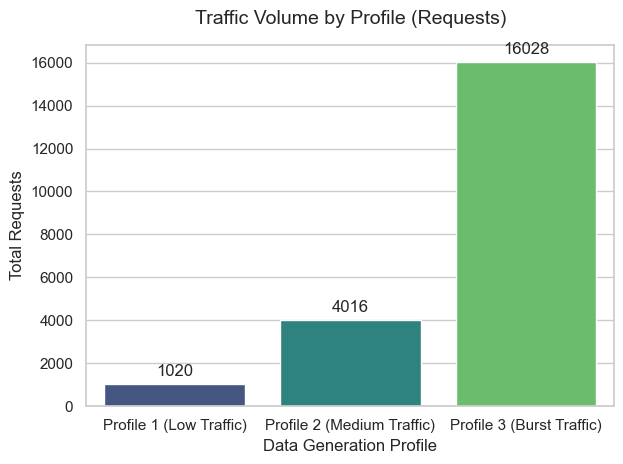

In [2]:
df_traffic = pd.read_csv('results/traffic_distributions.csv')
display(df_traffic)

ax = sns.barplot(
    data=df_traffic, 
    x='Profile', 
    y='Requests', 
    hue='Profile',
    palette='viridis', 
    legend=False
)

plt.title('Traffic Volume by Profile (Requests)', fontsize=14, pad=15)
plt.ylabel('Total Requests', fontsize=12)
plt.xlabel('Data Generation Profile', fontsize=12)

# Annotate bars
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", 
                (p.get_x() + p.get_width() / 2., p.get_height()), 
                ha = 'center', va = 'center', 
                xytext = (0, 9), 
                textcoords = 'offset points')

plt.tight_layout()
plt.show()

## Section 2: Evaluation Benchmark (Trade-off Matrix)

A multi-objective visualization measuring the Two-Stage XGBoost mechanism natively balancing Acceptance Ratio vs. Latency against base heuristic algorithms.

,Algorithm,Acceptance_Ratio,Avg_Latency,Avg_Active_Nodes
0,GreedyPlacement,47.222222,13.882353,11.373737
1,SmartPlacement,43.981481,6.021053,11.383838
2,XGBoostPlacement,56.097561,9.008696,11.383838


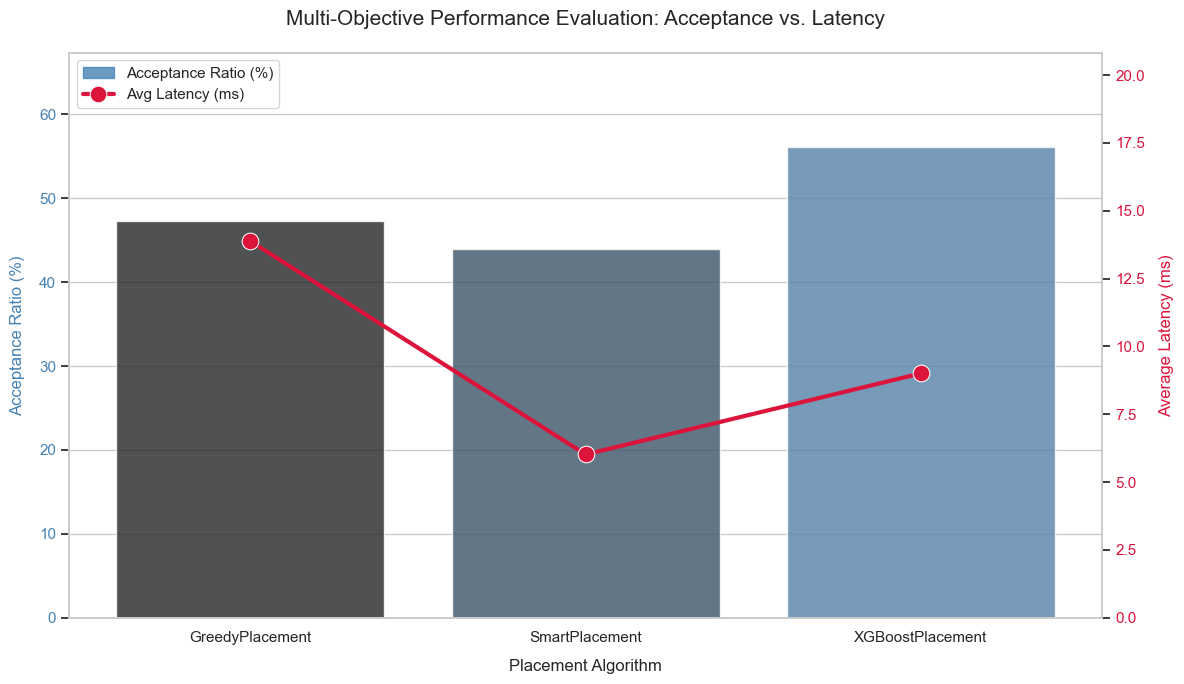

In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.patches as mpatches

df_metrics = pd.read_csv('results/evaluation_metrics.csv')
display(df_metrics)

fig, ax1 = plt.subplots(figsize=(12, 7))

# Bar Chart for Acceptance Ratio
sns.barplot(
    data=df_metrics, 
    x='Algorithm', 
    y='Acceptance_Ratio', 
    hue='Algorithm',
    palette='dark:steelblue', 
    alpha=0.8, 
    ax=ax1
)

# Customize Axis 1
ax1.set_ylabel('Acceptance Ratio (%)', fontsize=12, color='steelblue', labelpad=10)
ax1.set_xlabel('Placement Algorithm', fontsize=12, labelpad=10)
ax1.set_ylim(0, max(df_metrics['Acceptance_Ratio']) * 1.2)
ax1.tick_params(axis='y', labelcolor='steelblue')

# Line Plot for Avg Latency on secondary Y-axis
ax2 = ax1.twinx()
sns.lineplot(
    data=df_metrics, 
    x='Algorithm', 
    y='Avg_Latency', 
    color='crimson', 
    marker='o', 
    markersize=12, 
    linewidth=3, 
    ax=ax2,
    label='Avg Latency (ms)'
)

# Customize Axis 2
ax2.set_ylabel('Average Latency (ms)', fontsize=12, color='crimson', labelpad=10)
ax2.set_ylim(0, max(df_metrics['Avg_Latency']) * 1.5)
ax2.tick_params(axis='y', labelcolor='crimson')

plt.title('Multi-Objective Performance Evaluation: Acceptance vs. Latency', fontsize=15, pad=20)

# Create custom legend
lines_1 = [mpatches.Patch(color='steelblue', alpha=0.8)]
labels_1 = ['Acceptance Ratio (%)']
lines_2, labels_2 = ax2.get_legend_handles_labels()

# Explicitly remove the legend created by the barplot
ax1.get_legend()
ax1.legend(lines_1 + lines_2, labels_1 + labels_2, loc='upper left')

if ax2.get_legend():
    ax2.get_legend().remove()

ax2.grid(False) 
plt.tight_layout()
plt.show()